In [1]:
# ===========================================
# Exploratory Data Analysis (EDA)
# ===========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Settings
pd.set_option("display.max_columns", None)

plt.style.use("ggplot")

print("Libraries Loaded Successfully ✅")

Libraries Loaded Successfully ✅


In [2]:
# ===========================================
# Load Processed Dataset
# ===========================================

df = pd.read_csv("../data/processed/zomato_processed.csv")

print("Dataset Loaded Successfully ✅")

df.head()

Dataset Loaded Successfully ✅


,Restaurant,Reviewer,Review,Rating,Metadata,Time,Pictures,Name,Links,Cost,Collections,Cuisines,Timings
0,Beyond Flavours,Rusha Chakraborty,"The ambience was good, food was quite good . h...",5,"1 Review , 2 Followers",5/25/2019 15:54,0,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)"
1,Beyond Flavours,Anusha Tirumalaneedi,Ambience is too good for a pleasant evening. S...,5,"3 Reviews , 2 Followers",5/25/2019 14:20,0,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)"
2,Beyond Flavours,Ashok Shekhawat,A must try.. great food great ambience. Thnx f...,5,"2 Reviews , 3 Followers",5/24/2019 22:54,0,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)"
3,Beyond Flavours,Swapnil Sarkar,Soumen das and Arun was a great guy. Only beca...,5,"1 Review , 1 Follower",5/24/2019 22:11,0,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)"
4,Beyond Flavours,Dileep,Food is good.we ordered Kodi drumsticks and ba...,5,"3 Reviews , 2 Followers",5/24/2019 21:37,0,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)"


In [3]:
# ===========================================
# Dataset Overview
# ===========================================

print("Shape :", df.shape)

print("\n")

df.info()

print("\n")

df.describe(include="all")

Shape : (10000, 13)


<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Restaurant   10000 non-null  str  
 1   Reviewer     9962 non-null   str  
 2   Review       9955 non-null   str  
 3   Rating       9962 non-null   str  
 4   Metadata     9962 non-null   str  
 5   Time         9962 non-null   str  
 6   Pictures     10000 non-null  int64
 7   Name         10000 non-null  str  
 8   Links        10000 non-null  str  
 9   Cost         10000 non-null  str  
 10  Collections  5000 non-null   str  
 11  Cuisines     10000 non-null  str  
 12  Timings      9900 non-null   str  
dtypes: int64(1), str(12)
memory usage: 5.8 MB




,Restaurant,Reviewer,Review,Rating,Metadata,Time,Pictures,Name,Links,Cost,Collections,Cuisines,Timings
count,10000,9962,9955,9962,9962,9962,10000.000000,10000,10000,10000,5000,10000,9900
unique,100,7446,9364,10,2477,9782,NaN,100,100,28,42,89,74
top,Beyond Flavours,Ankita,good,5,1 Review,5/5/2019 22:39,NaN,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavou...,500,Food Hygiene Rated Restaurants in Hyderabad,"North Indian, Chinese",11 AM to 11 PM
freq,100,13,237,3832,919,3,NaN,100,100,1200,400,400,500
mean,NaN,NaN,NaN,NaN,NaN,NaN,0.748600,NaN,NaN,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,2.570381,NaN,NaN,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
# ===========================================
# Missing Values
# ===========================================

df.isnull().sum()

Restaurant        0
Reviewer         38
Review           45
Rating           38
Metadata         38
Time             38
Pictures          0
Name              0
Links             0
Cost              0
Collections    5000
Cuisines          0
Timings         100
dtype: int64

In [6]:
df["Rating"].unique()

<ArrowStringArray>
['5', '4', '1', '3', '2', '3.5', '4.5', '2.5', '1.5', 'Like', nan]
Length: 11, dtype: str

In [14]:
# ===========================================
# Clean Rating Column
# ===========================================

# Replace 'Like' with NaN
df["Rating"] = df["Rating"].replace("Like", np.nan)

# Convert to numeric
df["Rating"] = pd.to_numeric(df["Rating"], errors="coerce")

# Fill missing ratings with median
df["Rating"] = df["Rating"].fillna(df["Rating"].median())

print(df["Rating"].unique())

[5.  4.  1.  3.  2.  3.5 4.5 2.5 1.5]


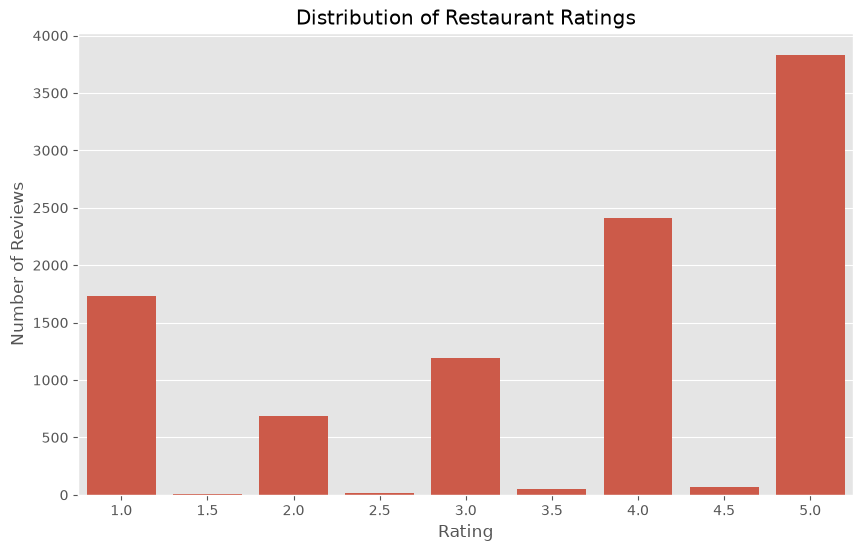

In [19]:
plt.figure(figsize=(10,6))

sns.countplot(
    data=df,
    x="Rating"
)

plt.title("Distribution of Restaurant Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")

plt.show()

In [20]:
# Convert Rating to numeric
df["Rating"] = pd.to_numeric(df["Rating"], errors="coerce")

# Fill missing ratings with median
df["Rating"] = df["Rating"].fillna(df["Rating"].median())

# Check
print(df["Rating"].dtype)

float64


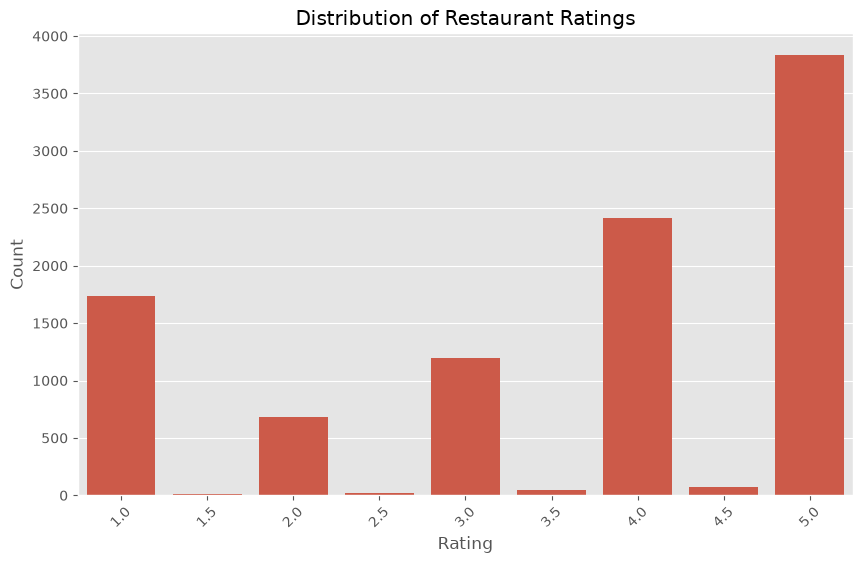

In [21]:
plt.figure(figsize=(10,6))

sns.countplot(
    data=df,
    x="Rating"
)

plt.title("Distribution of Restaurant Ratings")
plt.xlabel("Rating")
plt.ylabel("Count")

plt.xticks(rotation=45)

plt.show()

In [22]:
order=sorted(df["Rating"].unique())

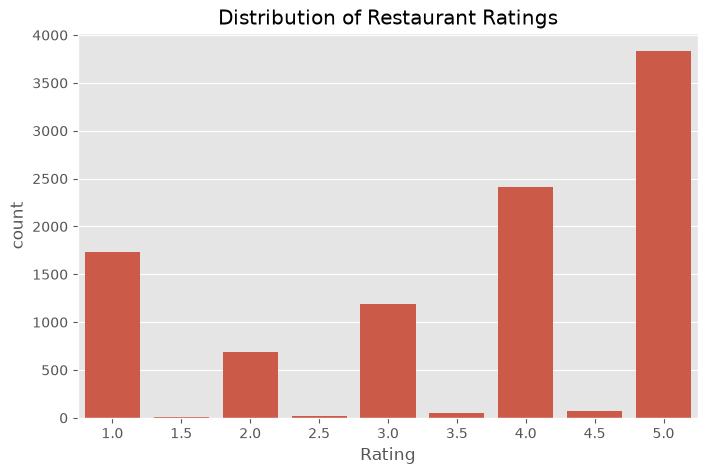

In [23]:
# ===========================================
# Rating Distribution
# ===========================================

plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="Rating",
    order=sorted(df["Rating"].unique())
)

plt.title("Distribution of Restaurant Ratings")

plt.show()